# 01 · Raw data overview

What the three sources contain before anything is cleaned: size, coverage, duplicates, the shape of
the activity measurements, and how much of the plant chemistry actually carries an antibacterial
measurement. Nothing is filtered or corrected here. Every cleaning decision belongs in
`02_curation.ipynb`, where it can be listed, changed and rerun.

**Sources.** ChEMBL (measured activity, CC BY-SA), LOTUS (plant to compound occurrences, CC0) and
the GBIF backbone (kingdom for each LOTUS organism, so plants can be told from bacteria and fungi).
All three are downloaded by `scripts/`; see [`../docs/data-sources.md`](../docs/data-sources.md).

**Output.** `data/processed/01_*.parquet`, read by `02_curation.ipynb`. Figures are written to
`figures/`, prefixed `01_`.

## 0. Settings

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from pipeline import data, viz

viz.use_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 120)

STANDARD_TYPE = os.environ.get("ETHNOHACK_STANDARD_TYPE", "mic")
ACTIVE_UGML = float(os.environ.get("ETHNOHACK_ACTIVE_UGML", 32))

pd.Series({
    "activity readout": STANDARD_TYPE.upper(),
    "activity threshold shown (ug/mL)": ACTIVE_UGML,
    "data directory": str(data.DATA),
    "activity files found": len(data.activity_files(STANDARD_TYPE)),
}, name="value").to_frame()

,value
activity readout,MIC
activity threshold shown (ug/mL),32.0
data directory,/Users/anagnole/Projects/ethnohack/data
activity files found,9


`ETHNOHACK_ACTIVE_UGML` only draws a reference line on the distributions below. It is shown here so
the number has one home; the labelling decision itself is made in `02_curation.ipynb`.

## 1. The three sources at a glance

In [2]:
activities = data.load_activities(STANDARD_TYPE)
lotus = data.load_lotus()
taxonomy = data.load_taxonomy()
targets = data.load_targets()

activities = activities.merge(
    targets[["target_chembl_id", "target_type", "uniprot_accessions"]],
    on="target_chembl_id", how="left")

overview = pd.DataFrame([
    {
        "source": "ChEMBL",
        "rows": len(activities),
        "compounds": activities.molecule_chembl_id.nunique(),
        "organisms": activities.target_organism.nunique(),
        "targets": activities.target_chembl_id.nunique(),
        "references": activities.document_chembl_id.nunique(),
    },
    {
        "source": "LOTUS",
        "rows": len(lotus),
        "compounds": lotus.structure_inchikey.nunique(),
        "organisms": lotus.organism_name.nunique(),
        "targets": np.nan,
        "references": lotus.reference_doi.nunique(),
    },
    {
        "source": "GBIF match",
        "rows": len(taxonomy),
        "compounds": np.nan,
        "organisms": taxonomy.organism_name.nunique(),
        "targets": np.nan,
        "references": np.nan,
    },
]).set_index("source")
display(overview)
pd.DataFrame(data.SOURCES).T

,rows,compounds,organisms,targets,references
source,,,,,
ChEMBL,462603,95689.0,9,46.0,7057.0
LOTUS,709740,227298.0,37467,NaN,91377.0
GBIF match,37468,NaN,37468,NaN,NaN


,what,licence,access
ChEMBL,"measured antibacterial activity, one row per a...",CC BY-SA 3.0,"REST API, scripts/fetch_chembl.py"
LOTUS,referenced taxon to natural-product occurrence...,CC0,"Zenodo frozen export, scripts/fetch_lotus.py"
GBIF backbone,kingdom and family for each LOTUS organism name,CC BY-NC 4.0 (name matching API),"species/match API, scripts/fetch_taxonomy.py"


## 2. ChEMBL: what kind of measurement is in each row

A row is one reported activity value. Before any of it can become a label, three things decide
whether the number is usable: the unit it is in, the relation (an exact `=`, or a censored `>` or
`<`), and whether ChEMBL itself flagged the row as suspect.

,rows,share
rows,462603,100.0%
with a numeric value,450888,97.5%
with a unit,451389,97.6%
with a pChEMBL value,0,0.0%
flagged by ChEMBL,2318,0.5%
flagged as potential duplicate,2,0.0%
with an activity comment,12935,2.8%


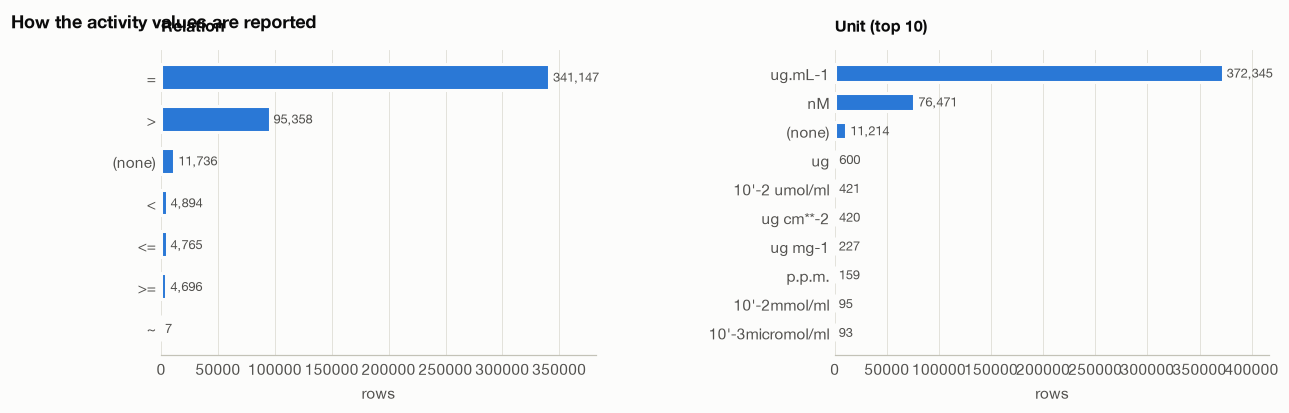

In [3]:
shape = pd.DataFrame({
    "rows": [len(activities)],
    "with a numeric value": [activities.standard_value.notna().sum()],
    "with a unit": [activities.standard_units.notna().sum()],
    "with a pChEMBL value": [activities.pchembl_value.notna().sum()],
    "flagged by ChEMBL": [activities.data_validity_comment.notna().sum()],
    "flagged as potential duplicate":
        [int(pd.to_numeric(activities.potential_duplicate, errors="coerce").fillna(0).sum())],
    "with an activity comment": [activities.activity_comment.notna().sum()],
}).T.rename(columns={0: "rows"})
shape["share"] = (shape.rows / len(activities)).map("{:.1%}".format)
display(shape)

relation = activities.standard_relation.fillna("(none)").value_counts()
units = activities.standard_units.fillna("(none)").value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw=dict(wspace=0.55))
viz.hbar(axes[0], list(relation.index), list(relation.values), xlabel="rows")
axes[0].set_title("Relation", fontsize=10.5)
viz.hbar(axes[1], list(units.index[:10]), list(units.values[:10]), xlabel="rows")
axes[1].set_title("Unit (top 10)", fontsize=10.5)
fig.suptitle("How the activity values are reported", x=0.02, ha="left", fontweight="bold")
viz.save(fig, "01_activity_reporting")
plt.show()

### 2a. Censored measurements

A `>` row means the compound did not inhibit growth at the highest concentration tested, so its true
MIC is unknown and merely above that value. These are the inactive compounds, and dropping them
would throw away most of the negative class. They cannot be treated as exact numbers either. The
count here sets how much the labelling step in 02 has to handle.

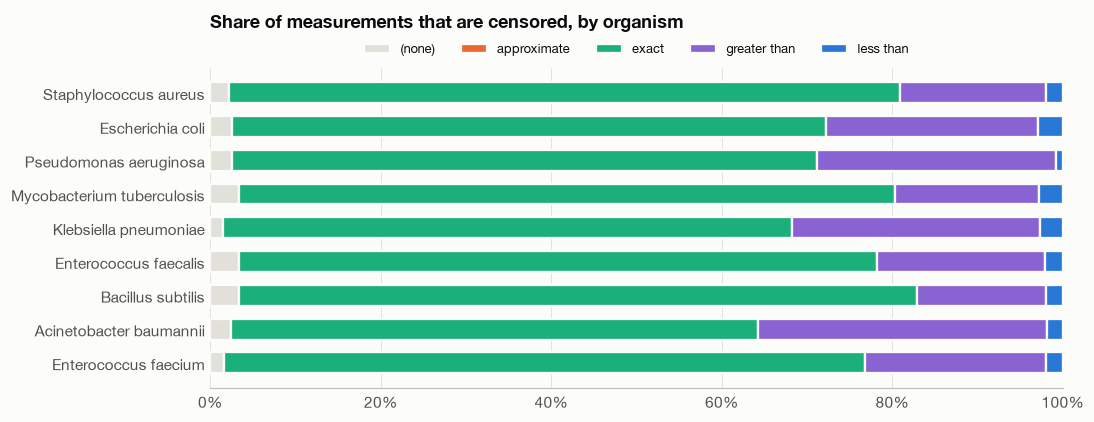

kind,(none),approximate,exact,greater than,less than
target_organism,,,,,
Staphylococcus aureus,3649,6,126520,27707,3074
Escherichia coli,2371,0,62709,22466,2553
Pseudomonas aeruginosa,1471,0,39715,16204,422
Mycobacterium tuberculosis,1635,0,36646,8022,1316
Klebsiella pneumoniae,461,0,20782,9063,824
Enterococcus faecalis,871,0,19429,5114,534
Bacillus subtilis,645,1,15309,2920,378
Acinetobacter baumannii,429,0,10918,5979,323
Enterococcus faecium,204,0,9119,2579,235


In [4]:
censored = activities.assign(
    kind=activities.standard_relation.map(
        {"=": "exact", ">": "greater than", "<": "less than", ">=": "greater than",
         "<=": "less than", "~": "approximate"}).fillna("(none)")
)
by_org = (censored.groupby(["target_organism", "kind"]).size()
          .unstack(fill_value=0))
by_org = by_org.loc[by_org.sum(axis=1).sort_values(ascending=False).index]
share = by_org.div(by_org.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, max(2.4, 0.42 * len(share))))
left = np.zeros(len(share))
for i, column in enumerate(share.columns):
    ax.barh(share.index, share[column], left=left, height=0.62,
            color=viz.SERIES[i % len(viz.SERIES)] if column != "(none)" else viz.GRID,
            edgecolor=viz.SURFACE, linewidth=1.5, label=column)
    left += share[column].to_numpy()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5, fontsize=8.5)
ax.set_title("Share of measurements that are censored, by organism", pad=26)
viz.save(fig, "01_censored_by_organism")
plt.show()
by_org

## 3. Coverage per organism

How many compounds each bacterium has been tested against. This is what decides which organisms can
carry a model of their own and which cannot.

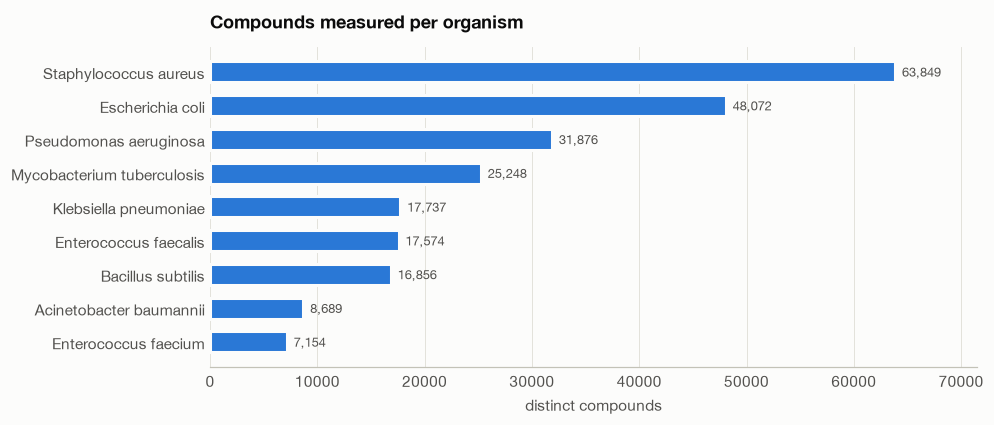

,rows,compounds,targets,references
target_organism,,,,
Staphylococcus aureus,160956,63849,11,4802
Escherichia coli,90099,48072,12,3844
Pseudomonas aeruginosa,57812,31876,6,2489
Mycobacterium tuberculosis,47619,25248,3,1440
Klebsiella pneumoniae,31130,17737,8,1450
Enterococcus faecalis,25948,17574,1,1368
Bacillus subtilis,19253,16856,1,1463
Acinetobacter baumannii,17649,8689,3,631
Enterococcus faecium,12137,7154,1,669


In [5]:
per_organism = activities.groupby("target_organism").agg(
    rows=("activity_id", "size"),
    compounds=("molecule_chembl_id", "nunique"),
    targets=("target_chembl_id", "nunique"),
    references=("document_chembl_id", "nunique"),
).sort_values("compounds", ascending=False)

fig, ax = plt.subplots(figsize=(9, max(2.4, 0.42 * len(per_organism))))
viz.hbar(ax, list(per_organism.index), list(per_organism.compounds), xlabel="distinct compounds")
ax.set_title("Compounds measured per organism")
viz.save(fig, "01_compounds_per_organism")
plt.show()
per_organism

## 4. Whole-organism against protein-target measurements

A MIC is usually measured against a living bacterium, not an isolated protein, so most of these
rows have a whole-organism target. ChEMBL records that in `target_type`, which has to be read from
the target endpoint: the `target_type` filter on the activity endpoint is ignored by the API and
returns the unfiltered count, so filtering there silently gives the wrong answer.

The split decides what can be modelled. A whole-organism label says "this compound stops this
bacterium growing", and there are many of them. A protein-target label says which protein it acts
on, which is what a mechanistic reading needs, and there are far fewer.

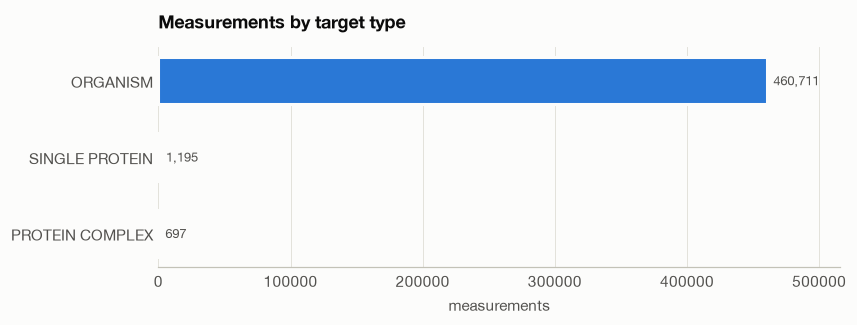

,rows,compounds,targets
target_type,,,
ORGANISM,460711,95329,9
SINGLE PROTEIN,1195,648,35
PROTEIN COMPLEX,697,199,2


In [6]:
split = activities.target_type.fillna("(unresolved)").value_counts()
fig, ax = plt.subplots(figsize=(8, 2.6))
viz.hbar(ax, list(split.index), list(split.values), xlabel="measurements")
ax.set_title("Measurements by target type")
viz.save(fig, "01_target_type")
plt.show()

activities.groupby(activities.target_type.fillna("(unresolved)")).agg(
    rows=("activity_id", "size"),
    compounds=("molecule_chembl_id", "nunique"),
    targets=("target_chembl_id", "nunique"),
).sort_values("rows", ascending=False)

### 4a. How thin the protein-target data is

The call chose per-target models with proteins grouped by mechanism of action. This is the evidence
for why that grouping is not optional.

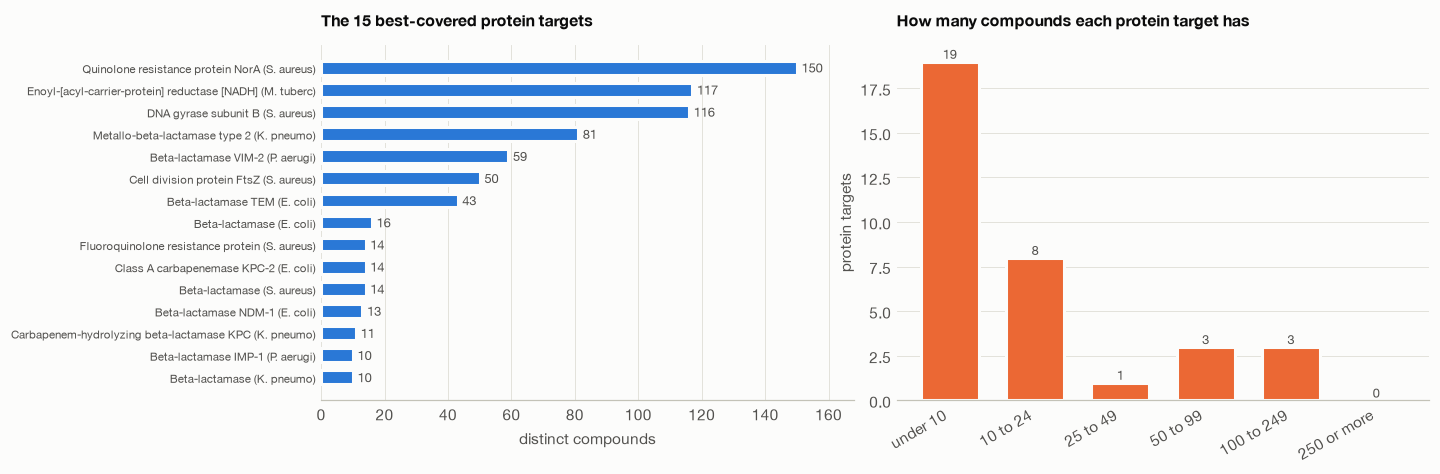

,value
protein targets,34.0
with fewer than 25 compounds,27.0
with 100 or more compounds,3.0
median compounds per protein target,8.0
compounds on the best-covered target,150.0


In [7]:
proteins = activities[activities.target_type.eq("SINGLE PROTEIN")]
protein_level = proteins.groupby(["target_organism", "target_pref_name"]).agg(
    compounds=("molecule_chembl_id", "nunique"),
    rows=("activity_id", "size"),
).sort_values("compounds", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(wspace=0.08, width_ratios=[1, 1]))
top = protein_level.head(15)
viz.hbar(axes[0], [f"{t} ({o.split()[0][0]}. {o.split()[-1][:6]})" for o, t in top.index],
         list(top.compounds), xlabel="distinct compounds")
axes[0].set_title("The 15 best-covered protein targets", fontsize=10.5)
axes[0].tick_params(axis="y", labelsize=7.5)

counts = protein_level.compounds
bins = [0, 10, 25, 50, 100, 250, 10 ** 9]
labels = ["under 10", "10 to 24", "25 to 49", "50 to 99", "100 to 249", "250 or more"]
grouped = pd.cut(counts, bins, labels=labels, right=False).value_counts().reindex(labels)
axes[1].bar(range(len(grouped)), grouped.values, width=0.68, color=viz.SERIES[1],
            edgecolor=viz.SURFACE, linewidth=2)
axes[1].set_xticks(range(len(grouped)), labels, rotation=30, ha="right")
axes[1].set_ylabel("protein targets")
axes[1].grid(axis="x", visible=False)
for i, v in enumerate(grouped.values):
    axes[1].text(i, v, str(v), ha="center", va="bottom", fontsize=8.5, color=viz.INK_SECONDARY)
axes[1].set_title("How many compounds each protein target has", fontsize=10.5)
viz.save(fig, "01_target_coverage")
plt.show()

pd.Series({
    "protein targets": len(protein_level),
    "with fewer than 25 compounds": int((protein_level.compounds < 25).sum()),
    "with 100 or more compounds": int((protein_level.compounds >= 100).sum()),
    "median compounds per protein target": float(protein_level.compounds.median()),
    "compounds on the best-covered target": int(protein_level.compounds.max()),
}, name="value").to_frame()

## 5. The activity values themselves

MIC on a log scale, which is how a two-fold dilution series is actually read. The reference line is
`ACTIVE_UGML`.

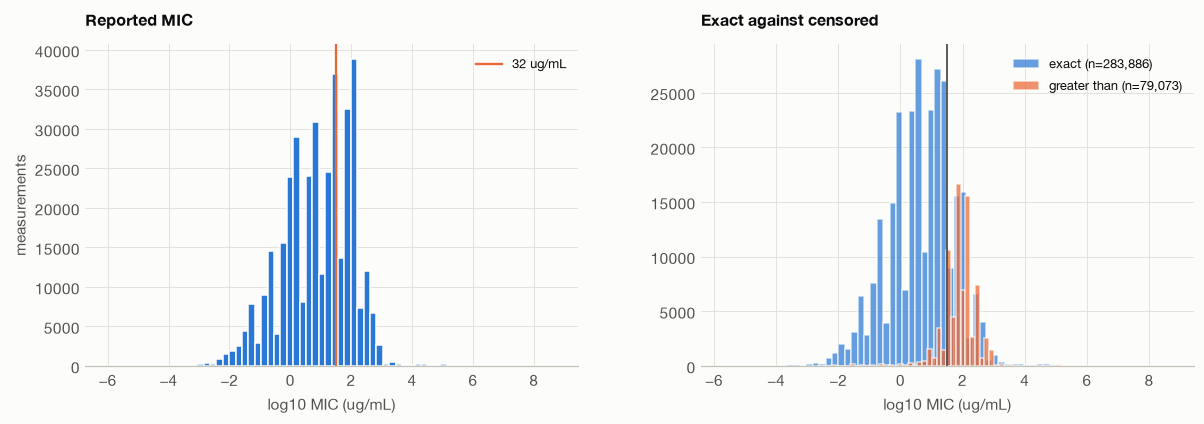

,value
rows in ug/mL,371665
median MIC (ug/mL),12.0
at or below 32 ug/mL,255020
share at or below 32,68.6%
distinct units across all rows,37


In [8]:
ug = activities[activities.standard_units.isin(["ug.mL-1", "ug ml-1", "ug/ml"])]
ug = ug[ug.standard_value.gt(0)]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(wspace=0.25))
axes[0].hist(np.log10(ug.standard_value), bins=70, color=viz.SERIES[0], edgecolor=viz.SURFACE)
axes[0].axvline(np.log10(ACTIVE_UGML), color=viz.SERIES[1], linewidth=1.5,
                label=f"{ACTIVE_UGML:g} ug/mL")
axes[0].set_xlabel("log10 MIC (ug/mL)")
axes[0].set_ylabel("measurements")
axes[0].legend(fontsize=8.5)
axes[0].set_title("Reported MIC", fontsize=10.5)

exact = ug[ug.standard_relation.eq("=")]
cens = ug[ug.standard_relation.isin([">", ">="])]
for i, (name, frame) in enumerate([("exact", exact), ("greater than", cens)]):
    if len(frame):
        axes[1].hist(np.log10(frame.standard_value), bins=70, alpha=0.72,
                     color=viz.SERIES[i], edgecolor=viz.SURFACE, label=f"{name} (n={len(frame):,})")
axes[1].axvline(np.log10(ACTIVE_UGML), color=viz.INK_SECONDARY, linewidth=1.2)
axes[1].set_xlabel("log10 MIC (ug/mL)")
axes[1].legend(fontsize=8.5)
axes[1].set_title("Exact against censored", fontsize=10.5)
viz.save(fig, "01_mic_distribution")
plt.show()

pd.Series({
    "rows in ug/mL": len(ug),
    "median MIC (ug/mL)": round(float(ug.standard_value.median()), 2),
    f"at or below {ACTIVE_UGML:g} ug/mL": int((ug.standard_value <= ACTIVE_UGML).sum()),
    f"share at or below {ACTIVE_UGML:g}": f"{(ug.standard_value <= ACTIVE_UGML).mean():.1%}",
    "distinct units across all rows": int(activities.standard_units.nunique()),
}, name="value").to_frame()

## 6. Duplicate measurements

The same compound tested against the same organism appears many times, from different papers and at
different readouts. That is replication rather than error, but it means a naive row count overstates
how much independent evidence there is, and the curation step has to collapse it.

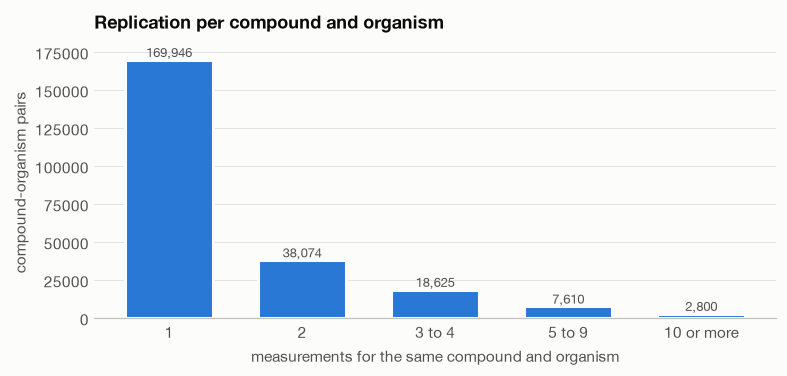

,value
compound-organism pairs,237055.0
measured once,169946.0
measured 10 or more times,2800.0
rows per pair (median),1.0


In [9]:
pairs = activities.groupby(["molecule_chembl_id", "target_organism"]).agg(
    measurements=("activity_id", "size"),
    references=("document_chembl_id", "nunique"),
)
bins = [1, 2, 3, 5, 10, 10 ** 9]
labels = ["1", "2", "3 to 4", "5 to 9", "10 or more"]
spread = pd.cut(pairs.measurements, bins, labels=labels, right=False).value_counts().reindex(labels)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(len(spread)), spread.values, width=0.66, color=viz.SERIES[0],
       edgecolor=viz.SURFACE, linewidth=2)
ax.set_xticks(range(len(spread)), labels)
ax.set_xlabel("measurements for the same compound and organism")
ax.set_ylabel("compound-organism pairs")
ax.grid(axis="x", visible=False)
for i, v in enumerate(spread.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8.5, color=viz.INK_SECONDARY)
ax.set_title("Replication per compound and organism")
viz.save(fig, "01_replication")
plt.show()

pd.Series({
    "compound-organism pairs": len(pairs),
    "measured once": int((pairs.measurements == 1).sum()),
    "measured 10 or more times": int((pairs.measurements >= 10).sum()),
    "rows per pair (median)": float(pairs.measurements.median()),
}, name="value").to_frame()

## 7. LOTUS: the plant side

LOTUS pairs a structure with the organism it was reported in, each pair backed by a reference. It
covers every kingdom, so something has to separate plants from the fungal and animal metabolites
that would otherwise be counted as plant natural products.

Two independent taxonomies are used and compared: the one LOTUS ships with the data (land plants
are the phylum `Streptophyta`) and the GBIF backbone matched by name. Agreement between them is a
quality check on the filter; a record counts as a plant if either says so, which recovers the
organisms LOTUS leaves blank.

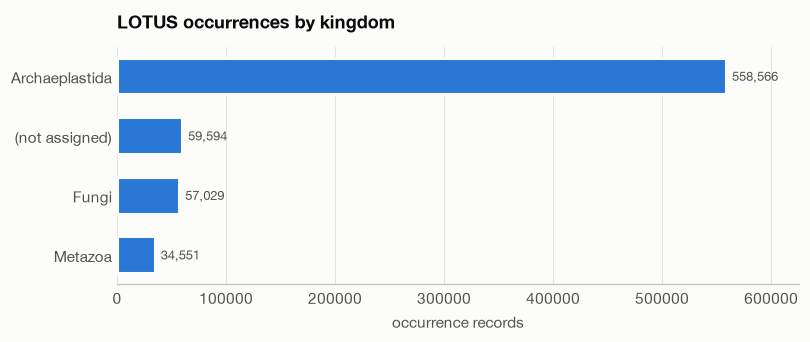

plant_gbif,GBIF: not a plant,GBIF: plant
plant_lotus,,
LOTUS: not a plant,138319,19227
LOTUS: plant,1541,550653


,value
LOTUS occurrence records,709740
distinct structures,227298
distinct organisms,37467
records LOTUS leaves without a kingdom,59594
organisms LOTUS leaves without a kingdom,3136
plant records (either taxonomy),571421
of which both taxonomies agree,550653
distinct plant species,28736
distinct plant families,533
distinct structures from plants,153745


In [10]:
lotus_tax = data.mark_plants(lotus, taxonomy)
kingdom = lotus_tax.kingdom.fillna("(not assigned)").value_counts()

fig, ax = plt.subplots(figsize=(8, 2.8))
viz.hbar(ax, list(kingdom.index), list(kingdom.values), xlabel="occurrence records")
ax.set_title("LOTUS occurrences by kingdom")
viz.save(fig, "01_lotus_kingdoms")
plt.show()

agreement = pd.crosstab(
    lotus_tax.plant_lotus.map({True: "LOTUS: plant", False: "LOTUS: not a plant"}),
    lotus_tax.plant_gbif.map({True: "GBIF: plant", False: "GBIF: not a plant"}),
)
display(agreement)

plants = lotus_tax[lotus_tax.is_plant]
pd.Series({
    "LOTUS occurrence records": len(lotus_tax),
    "distinct structures": lotus_tax.structure_inchikey.nunique(),
    "distinct organisms": lotus_tax.organism_name.nunique(),
    "records LOTUS leaves without a kingdom": int(lotus_tax.kingdom.isna().sum()),
    "organisms LOTUS leaves without a kingdom":
        int(lotus_tax.loc[lotus_tax.kingdom.isna(), "organism_name"].nunique()),
    "plant records (either taxonomy)": len(plants),
    "of which both taxonomies agree": int((plants.plant_lotus & plants.plant_gbif).sum()),
    "distinct plant species": plants.organism_name.nunique(),
    "distinct plant families": plants.family.nunique(),
    "distinct structures from plants": plants.structure_inchikey.nunique(),
    "plant structures with a SMILES": plants[plants.structure_smiles.notna()]
        .structure_inchikey.nunique(),
}, name="value").to_frame()

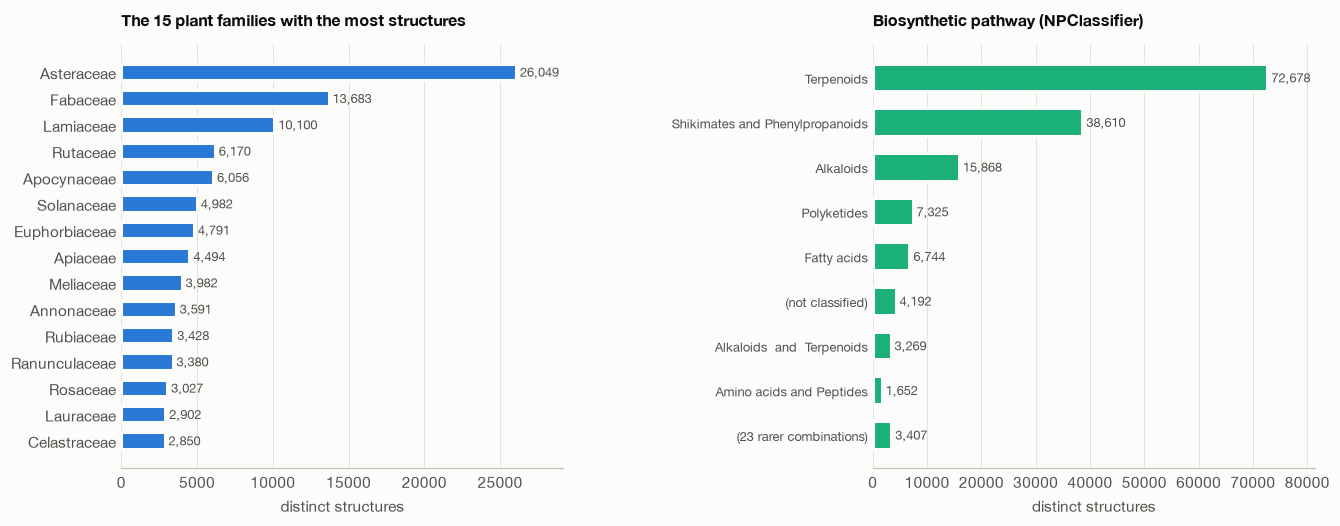

,structures,species
family,,
Asteraceae,26049,4283
Fabaceae,13683,2561
Lamiaceae,10100,1343
Rutaceae,6170,692
Apocynaceae,6056,596
Solanaceae,4982,455
Euphorbiaceae,4791,486
Apiaceae,4494,595
Meliaceae,3982,202


In [11]:
by_family = plants.groupby("family").agg(
    structures=("structure_inchikey", "nunique"),
    species=("organism_name", "nunique"),
).sort_values("structures", ascending=False).head(15)

unique_plant_structures = plants.drop_duplicates("structure_inchikey")
pathway = (unique_plant_structures.np_pathway.fillna("(not classified)")
           .str.replace("$", " and ", regex=False)
           .value_counts())
top_pathways = pathway.head(8)
if len(pathway) > 8:
    top_pathways = pd.concat([
        top_pathways,
        pd.Series({f"({len(pathway) - 8} rarer combinations)": pathway[8:].sum()}),
    ])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw=dict(wspace=0.7))
viz.hbar(axes[0], list(by_family.index), list(by_family.structures), xlabel="distinct structures")
axes[0].set_title("The 15 plant families with the most structures", fontsize=10.5)
viz.hbar(axes[1], list(top_pathways.index), list(top_pathways.values), color=viz.SERIES[2],
         xlabel="distinct structures")
axes[1].set_title("Biosynthetic pathway (NPClassifier)", fontsize=10.5)
axes[1].tick_params(axis="y", labelsize=8.5)
viz.save(fig, "01_plant_families")
plt.show()
by_family

## 8. The join: plant chemistry that carries an antibacterial measurement

This is the number the whole project rests on. ChEMBL identifies compounds by its own id, LOTUS by
InChIKey, so the join needs an InChIKey for every ChEMBL structure. RDKit computes it from the
canonical SMILES in the activity record.

In [12]:
smiles = activities[["molecule_chembl_id", "canonical_smiles"]].drop_duplicates("molecule_chembl_id")
smiles = smiles[smiles.canonical_smiles.notna()].reset_index(drop=True)
print(f"computing InChIKeys for {len(smiles):,} distinct ChEMBL structures")
smiles["inchikey"] = data.inchikeys(smiles.canonical_smiles, show_progress=True)
print(f"  failed to parse: {smiles.inchikey.isna().sum():,}")

plant_keys = set(plants.structure_inchikey.dropna())
smiles["from_plant"] = smiles.inchikey.isin(plant_keys)

labelled = activities.merge(smiles[["molecule_chembl_id", "inchikey", "from_plant"]],
                            on="molecule_chembl_id", how="left")
labelled["from_plant"] = labelled.from_plant.fillna(False).astype(bool)

pd.Series({
    "ChEMBL structures tested against these bacteria": len(smiles),
    "of those, recorded in a plant by LOTUS": int(smiles.from_plant.sum()),
    "share": f"{smiles.from_plant.mean():.1%}",
    "activity rows on plant-derived compounds": int(labelled.from_plant.sum()),
    "distinct plant species contributing them":
        int(plants[plants.structure_inchikey.isin(set(smiles[smiles.from_plant].inchikey))]
            .organism_name.nunique()),
}, name="value").to_frame()

computing InChIKeys for 95,529 distinct ChEMBL structures


  inchikeys 20,000/95,527


  inchikeys 40,000/95,527


  inchikeys 60,000/95,527


  inchikeys 80,000/95,527


  failed to parse: 1


,value
ChEMBL structures tested against these bacteria,95529
"of those, recorded in a plant by LOTUS",2157
share,2.3%
activity rows on plant-derived compounds,29672
distinct plant species contributing them,15110


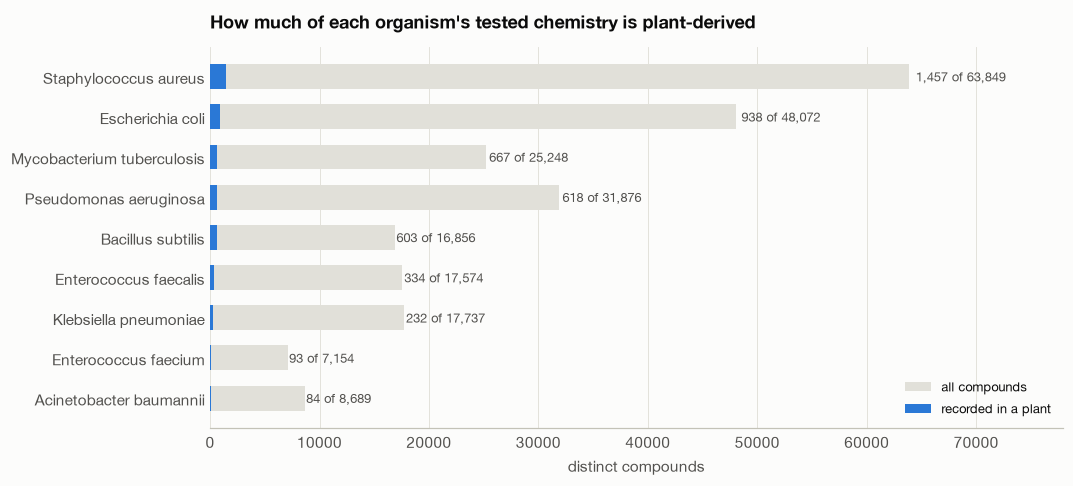

,compounds,rows
target_organism,,
Staphylococcus aureus,1457,11944
Escherichia coli,938,6133
Mycobacterium tuberculosis,667,2664
Pseudomonas aeruginosa,618,2638
Bacillus subtilis,603,1424
Enterococcus faecalis,334,1646
Klebsiella pneumoniae,232,1591
Enterococcus faecium,93,831
Acinetobacter baumannii,84,801


In [13]:
joined = labelled[labelled.from_plant]
per_org_plant = joined.groupby("target_organism").agg(
    compounds=("molecule_chembl_id", "nunique"),
    rows=("activity_id", "size"),
).sort_values("compounds", ascending=False)
all_counts = per_organism.compounds.reindex(per_org_plant.index)

fig, ax = plt.subplots(figsize=(10, max(2.6, 0.5 * len(per_org_plant))))
y = np.arange(len(per_org_plant))
ax.barh(y, all_counts.values, height=0.62, color=viz.GRID, label="all compounds")
ax.barh(y, per_org_plant.compounds.values, height=0.62, color=viz.SERIES[0],
        label="recorded in a plant")
ax.set_yticks(y, list(per_org_plant.index))
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
for i, (a, p) in enumerate(zip(all_counts.values, per_org_plant.compounds.values)):
    ax.text(a * 1.01, i, f"{p:,} of {a:,}", va="center", fontsize=8.5, color=viz.INK_SECONDARY)
ax.set_xlim(0, all_counts.max() * 1.22)
ax.set_xlabel("distinct compounds")
ax.legend(fontsize=8.5, loc="lower right")
ax.set_title("How much of each organism's tested chemistry is plant-derived")
viz.save(fig, "01_plant_overlap")
plt.show()
per_org_plant

### 8a. How different is plant chemistry from the chemistry the model would learn from

The training set is whatever has been measured, which is mostly synthetic medicinal chemistry. The
screening set is plant natural products. If the two occupy different regions of chemical space,
a model scored on a random split of the training set will overstate how well it ranks plants.

Four cheap descriptors are enough to show it: molecular weight, lipophilicity (logP), hydrogen-bond
donors and rotatable bonds. They are computed with RDKit on three groups: everything with a
measured MIC, the plant-derived subset of that, and the plant structures with no measurement at
all, which is what the model would actually be asked to rank.

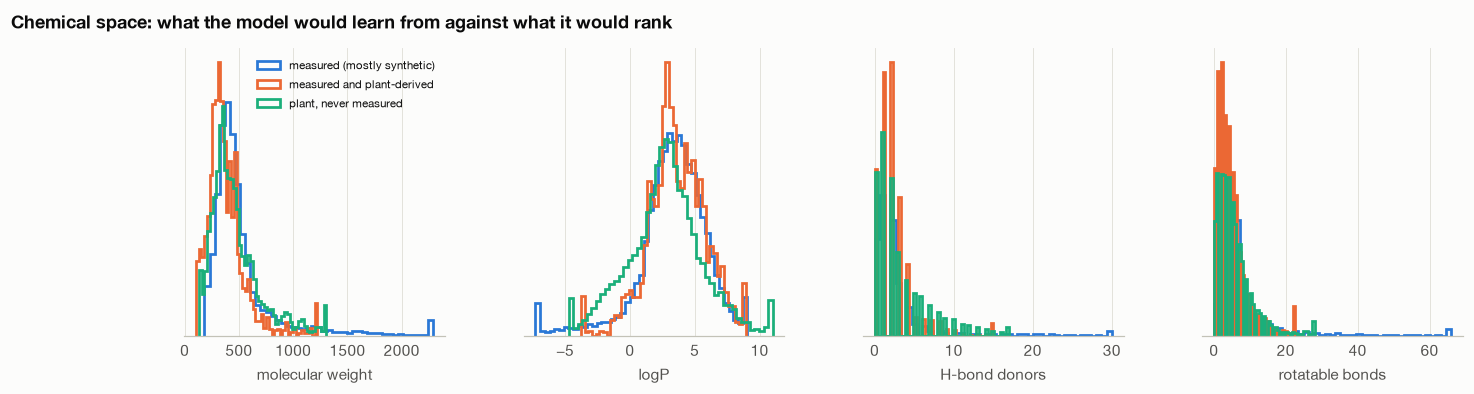

,molecular weight,logP,H-bond donors,rotatable bonds
group,,,,
measured (mostly synthetic),429.2,3.5,2.0,5.0
measured and plant-derived,338.4,3.5,2.0,3.0
"plant, never measured",406.5,2.8,2.0,4.0


In [14]:
from rdkit import Chem, RDLogger
from rdkit.Chem import Crippen, Descriptors, Lipinski

RDLogger.DisableLog("rdApp.*")

DESCRIPTORS = {
    "molecular weight": Descriptors.MolWt,
    "logP": Crippen.MolLogP,
    "H-bond donors": Lipinski.NumHDonors,
    "rotatable bonds": Lipinski.NumRotatableBonds,
}


def describe(smiles_series, label, limit=30000, seed=0):
    values = smiles_series.dropna().drop_duplicates()
    if len(values) > limit:
        values = values.sample(limit, random_state=seed)
    rows = []
    for text in values:
        mol = Chem.MolFromSmiles(text)
        if mol is None:
            continue
        rows.append({name: fn(mol) for name, fn in DESCRIPTORS.items()})
    return pd.DataFrame(rows).assign(group=label)


measured_smiles = smiles.canonical_smiles
measured_plant_smiles = smiles.loc[smiles.from_plant, "canonical_smiles"]
unmeasured_plant_smiles = unique_plant_structures.loc[
    ~unique_plant_structures.structure_inchikey.isin(set(smiles.inchikey.dropna())),
    "structure_smiles"]

space = pd.concat([
    describe(measured_smiles, "measured (mostly synthetic)"),
    describe(measured_plant_smiles, "measured and plant-derived"),
    describe(unmeasured_plant_smiles, "plant, never measured"),
], ignore_index=True)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), gridspec_kw=dict(wspace=0.3))
groups = list(space.group.unique())
for ax, name in zip(axes, DESCRIPTORS):
    for i, g in enumerate(groups):
        values = space.loc[space.group.eq(g), name]
        lo, hi = values.quantile([0.01, 0.99])
        ax.hist(values.clip(lo, hi), bins=45, histtype="step", linewidth=1.8,
                density=True, color=viz.SERIES[i], label=g)
    ax.set_xlabel(name)
    ax.set_yticks([])
axes[0].legend(fontsize=7.5, loc="upper right")
fig.suptitle("Chemical space: what the model would learn from against what it would rank",
             x=0.02, ha="left", fontweight="bold")
viz.save(fig, "01_chemical_space")
plt.show()

space.groupby("group")[list(DESCRIPTORS)].median().round(1).reindex(groups)

## 9. Save what 02 reads

Three tables. Nothing has been cleaned, deduplicated or labelled; that is 02's job. The InChIKey
mapping is saved because recomputing it costs minutes.

In [15]:
plant_out = plants[[
    "structure_inchikey", "structure_smiles", "structure_exact_mass", "structure_xlogp",
    "np_pathway", "np_superclass", "np_class",
    "organism_name", "family", "genus", "reference_doi",
]]

written = {
    "01_activities": data.save_processed(labelled, "01_activities"),
    "01_structures": data.save_processed(smiles, "01_structures"),
    "01_plant_occurrences": data.save_processed(plant_out, "01_plant_occurrences"),
    "01_plant_structures": data.save_processed(
        plant_out.drop_duplicates("structure_inchikey").drop(
            columns=["organism_name", "family", "genus", "reference_doi"]),
        "01_plant_structures"),
}
pd.DataFrame([
    {"table": name, "rows": len(pd.read_parquet(path)), "path": str(path.relative_to(ROOT))}
    for name, path in written.items()
]).set_index("table")

,rows,path
table,,
01_activities,462603,data/processed/01_activities.parquet
01_structures,95529,data/processed/01_structures.parquet
01_plant_occurrences,571421,data/processed/01_plant_occurrences.parquet
01_plant_structures,153745,data/processed/01_plant_structures.parquet


## 10. What this data can and cannot support

**The label is whole-organism growth inhibition, not protein inhibition.** 460,711 of 462,603 MIC
rows (99.6%) are measured against a living bacterium. Across all nine organisms only 35
single-protein targets carry any MIC data at all (34 distinct organism-protein pairs), with a
median of 8 compounds each and 150 on the best-covered one. A per-target model cannot be trained on
this readout. The protein-level data exists in ChEMBL but under other readouts (IC50, Ki, percent
inhibition), and fetching it is a separate job. So the primary model predicts "does this compound
stop this bacterium growing", and the protein layer, if we build it, is a second and much smaller
dataset used to explain a shortlist rather than to rank it.

**No MIC row has a pChEMBL value.** ChEMBL computes pChEMBL only for selected activity types, and
MIC is not one of them. The usual quality filter `pchembl_value__isnull=false` would discard all
462,603 rows while looking like it was working. Potency has to be read from `standard_value` plus
`standard_units` plus `standard_relation` instead, which is what the organisers' own data guide
asks for.

**Inactivity is recorded as a censored value, and there is a lot of it.** 100,054 rows (21.6%) are
`>` or `>=` and 9,659 (2.1%) are `<` or `<=`. The greater-than rows are the compounds that failed
at the highest concentration tested, which is most of what we have in the way of a negative class.
They cannot be dropped without destroying the class balance and they cannot be treated as exact
numbers. 02 has to decide a rule and state it.

**Units are not consistent.** 37 distinct unit strings. 371,665 rows are already in µg/mL;
the rest need conversion or exclusion, and a µM to µg/mL conversion needs a molecular weight, which
is only as good as the structure record.

**The positive class is inflated by what gets published.** Median MIC is 12 µg/mL and 68.6% of
µg/mL values sit at or below 32. A threshold anywhere in the usual range labels most of the
dataset active, because papers report compounds that worked. Any accuracy figure has to be read
against that base rate, which is the strongest argument for the call's decision to judge the model
on precision at the top of the ranking rather than on overall accuracy.

**There is almost no replication to average over.** 169,946 of 237,055 compound-organism pairs
(71.7%) are measured exactly once, so for most compounds there is a single number and no way to
tell a careful measurement from a sloppy one. Only 2,800 pairs have ten or more measurements.

**Coverage per organism is very uneven.** From 63,849 compounds tested against *S. aureus* down to
7,154 against *E. faecium*. The four best-covered organisms carry most of the data. Grouping
organisms, or accepting that the smaller ones get weaker models, is a decision 02 or 03 has to
make explicitly.

**The plant filter is solid.** The two taxonomies agree on 550,653 occurrence records. GBIF adds
19,227 that LOTUS leaves unassigned and LOTUS adds 1,541 that GBIF does not match, so the union is
571,421 records over 28,736 species and 533 families, yielding 153,745 distinct plant structures.
Every one of them has a SMILES, so the screening set is usable as it stands.

**The plant overlap is 2.3%, and that shapes the project.** Of 95,529 compounds with a measured
MIC, only 2,157 are recorded in a plant. Set against 153,745 plant structures with no antibacterial
measurement at all, this is a virtual screen: the labelled data is overwhelmingly synthetic
medicinal chemistry and the thing we want to rank is plant chemistry.

**But the two are not as far apart as that framing suggests, and the measurement matters more
than the intuition.** On bulk descriptors the distributions overlap heavily. Median molecular
weight is 429 for the measured set against 406 for unmeasured plant structures, median logP 3.5
against 2.8, H-bond donors 2 in both, rotatable bonds 5 against 4. Plant chemistry skews more
polar with a longer tail of hydrogen-bond donors, which is what glycosides look like, and it lacks
the very high molecular weight tail of the synthetic set. So the transfer problem is real but
moderate, not a leap into unrelated chemistry.

Two things follow. The 2,157 plant-derived compounds that do carry a measurement are the only
direct evidence of transfer, so they are worth more as a held-out plant-chemistry test set than as
training rows. And the similarity-clustered split the call chose is necessary rather than
decorative: the risk inside the training set is not synthetic-against-natural, it is that
near-identical analogues from one medicinal-chemistry paper land on both sides of a random split.

**What this cannot support.** Any claim about clinical efficacy, dosing, or what a plant extract
does as a whole. The data is purified single compounds against bacteria in a plate. Synergy between
the compounds in a real extract, which is the part of the Track 2 brief that makes plant medicine
interesting, is not measurable from anything here.

### What 02 has to decide

| decision | why it is not obvious |
|---|---|
| the active/inactive threshold | 68.6% of values fall below 32 µg/mL, so the threshold sets the class balance |
| how censored rows are used | 23.7% of the data; dropping the greater-than rows removes most negatives |
| which units to convert and which to drop | 37 unit strings, and µM conversion needs a molecular weight |
| how repeated measurements collapse to one label | median 1 per pair, but 2,800 pairs have 10 or more |
| whether to model organisms separately or together | coverage ranges from 63,849 to 7,154 compounds |
| whether plant-derived compounds are held out | 2,157 of them, and they are the only test of transfer |